# 10 · From Single Cells to NumPy Batches

**NHyDB 0.27.1 notebook series · v1**

The address mathematics tells NHyDB *where* a value lives; the Rust engine decides *how fast* it gets there. This notebook writes and reads the same records one by one, as a batch and as NumPy columns, measures what each way costs in time and in bytes, and shows the shapes and data types that come back.

> **Who is this for?** This notebook starts with a short introduction and continues with runnable examples. **New to NHyDB?** Read from top to bottom – every idea is introduced before it is used. **Already know the basics?** Skip the sections marked 📘 *Background* and jump to the experiments marked ▶. All cells run from top to bottom; optional deep dives are marked ⏩ *Advanced*.

**What you will learn**

* the three write paths: single calls, `put_dense_batch`, `put_numpy_batch`
* the read paths: `get_record`, `range`, `read_numpy` – and what `_present` means
* how many bytes a record costs on disk, depending on how it was written
* NumPy for any layout (`put_objects_numpy`), sparse cells (`put_cells_numpy`), MATH (`put_math_numpy`) and SQL (`sql_numpy`)

**Recommended before:** [02 · From Mathematics to Stored Values](02_from_address_to_data_v1.ipynb).

### Setup

The next cell checks the environment and defines a few small plotting helpers used in
this notebook. It is collapsed because it is not about NHyDB itself – feel free to open
it. Every database in this notebook lives in a temporary folder that is removed at
the end.

In [1]:
import math
import os
import shutil
import sys
import tempfile

import matplotlib
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch, Rectangle

import nhydb

# --- environment check ---------------------------------------------------------
EXPECTED = "0.27.1"
print(f"Python {sys.version.split()[0]} · nhydb {nhydb.ENGINE_VERSION} · "
      f"file format {nhydb.FILE_FORMAT_VERSION} · matplotlib {matplotlib.__version__}")
if nhydb.ENGINE_VERSION != EXPECTED:
    print(f"⚠ This notebook was written for NHyDB {EXPECTED}; results may differ.")

# --- a private temporary folder for all databases of this notebook --------------
WORKDIR = tempfile.mkdtemp(prefix="nhydb_notebook_")


def db_path(name):
    """Path of a new database file inside the temporary folder."""
    return os.path.join(WORKDIR, name)


def cleanup():
    shutil.rmtree(WORKDIR, ignore_errors=True)


def file_sizes(path):
    """Sizes of the files that belong to a database (bytes)."""
    folder, base = os.path.split(path)
    return {f: os.path.getsize(os.path.join(folder, f))
            for f in sorted(os.listdir(folder)) if f.startswith(base)}


# --- one visual language for the whole series -----------------------------------
# Layer A (mathematical address space) = blue tones, layer B (logical data model) =
# green, layer C (storage engine) = slate grey. Lanes and boundary points belong to A.
COLORS = {
    "A": "#1d4ed8", "A_light": "#dbeafe",
    "B": "#15803d", "B_light": "#dcfce7",
    "C": "#475569", "C_light": "#e2e8f0",
    "NL": "#2563eb", "NR": "#7c3aed",
    "GZ": "#dc2626", "N0": "#9ca3af",
    "attention": "#ea580c", "ok": "#16a34a", "bad": "#dc2626",
}
plt.rcParams.update({
    "figure.dpi": 100, "savefig.dpi": 100, "font.size": 10,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.titleweight": "bold", "axes.titlesize": 11,
})

import statistics
import time

import numpy as np
import pandas as pd
from nhydb.math import MathMap, MathMapLayoutSpec
from nhydb.query import Q, QueryEngine

FIELDS = [{"v": 1, "name": "t", "type": "u64"}, {"v": 2, "name": "temp", "type": "f32"},
          {"v": 3, "name": "ok", "type": "bool"}, {"v": 4, "name": "station", "type": "utf8"}]


def new_sensor_db(name):
    """A fresh database with one CLASSIC layout 'samples' (record = u)."""
    path = db_path(name)
    db = nhydb.create(path, overwrite=True)
    db.create_realm(1, "sensors")
    db.create_shape(1, 1, "sample", FIELDS)
    db.create_classic_layout(1, 1, "samples", shape_id=1)
    return db, path


def columns(n):
    """n synthetic samples as NumPy columns: a time stamp, a temperature curve, a flag, a station."""
    t = np.arange(n, dtype=np.uint64) * 60
    return {"t": t,
            "temp": (20 + 5 * np.sin(t / 3600.0)).astype(np.float32),
            "ok": t % 7 != 0,
            "station": np.array(["A", "B", "C", "D"] * (n // 4) + ["A", "B", "C"][: n % 4], dtype=object)}

Python 3.14.5 · nhydb 0.27.1 · file format 0.16 · matplotlib 3.11.2


## 📘 Background: where the time goes

Every call from Python into the engine has a fixed cost (argument conversion, locking, one
small write). For one record that cost dominates; for a million records it should be paid
**once**. That is what batches do:

| Path | One call writes | Data travels as |
|---|---|---|
| `put_record` / `put_cell` | one record / one cell | Python objects |
| `put_dense_batch` | many consecutive records | a Python list of rows |
| `put_numpy_batch` | many consecutive records | NumPy **columns** – encoding and loops run in Rust |

All three end in the same cells with the same numbers `N` – only the **path through layer C**
differs.

## 1 · Three ways to write the same records

**Question:** How much faster is a batch than a loop of single calls?

▶ **Run it:** for 10 … 100,000 records we write the same samples three ways, commit once at the
end, and repeat each measurement three times (the median is shown). Timings depend on your
machine – these are measurements, not promises.

In [2]:
# ▶ Try it: sizes and repetitions (larger sizes take longer)
SIZES = [10, 100, 1_000, 10_000, 100_000]
REPEATS = 3


def write_single(n):
    db, path = new_sensor_db("single.nhydb")
    cols = columns(n)
    rows = [{k: cols[k][i].item() if hasattr(cols[k][i], "item") else cols[k][i] for k in cols} for i in range(n)]
    t0 = time.perf_counter()
    for i, row in enumerate(rows):
        db.put_record(1, i + 1, row)
    db.commit()
    seconds = time.perf_counter() - t0
    db.close()
    return seconds, path


def write_batch(n):
    db, path = new_sensor_db("batch.nhydb")
    cols = columns(n)
    rows = [[int(cols["t"][i]), float(cols["temp"][i]), bool(cols["ok"][i]), cols["station"][i]] for i in range(n)]
    t0 = time.perf_counter()
    db.put_dense_batch(1, 1, rows, shape_id=1)
    db.commit()
    seconds = time.perf_counter() - t0
    db.close()
    return seconds, path


def write_numpy(n):
    db, path = new_sensor_db("numpy.nhydb")
    cols = columns(n)
    t0 = time.perf_counter()
    db.put_numpy_batch(1, 1, cols, shape_id=1)
    db.commit()
    seconds = time.perf_counter() - t0
    db.close()
    return seconds, path


results = []
for n in SIZES:
    for name, fn in (("single put_record", write_single), ("put_dense_batch", write_batch),
                     ("put_numpy_batch", write_numpy)):
        times = []
        for _ in range(REPEATS):
            seconds, path = fn(n)
            times.append(seconds)
        size = os.path.getsize(path)
        with nhydb.open(path) as db:                            # every path stored the same data
            assert db.get_record(1, n)["t"] == (n - 1) * 60
        results.append({"records": n, "path": name, "median s": statistics.median(times),
                        "records/s": n / statistics.median(times), "file bytes": size})

writes = pd.DataFrame(results)
writes.pivot(index="records", columns="path", values="records/s").round(0)

path,put_dense_batch,put_numpy_batch,single put_record
records,,,
10,36485.0,36552.0,33793.0
100,364853.0,362264.0,220386.0
1000,2480110.0,2639978.0,569733.0
10000,7733204.0,8731078.0,705357.0
100000,9406269.0,10615383.0,699941.0


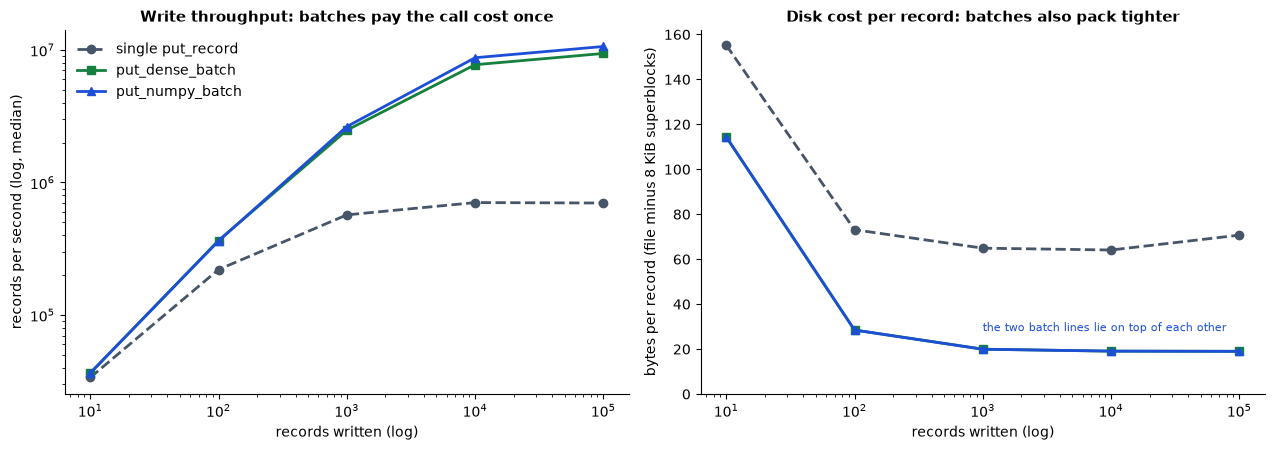

at 100,000 records: numpy batch is 15× faster than single calls; bytes per record {'single put_record': 70.7, 'put_dense_batch': 19.0, 'put_numpy_batch': 19.0}


In [3]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.6))
styles = {"single put_record": ("o--", COLORS["C"]), "put_dense_batch": ("s-", COLORS["B"]),
          "put_numpy_batch": ("^-", COLORS["A"])}
for name, (marker, color) in styles.items():
    part = writes[writes["path"] == name]
    ax1.loglog(part["records"], part["records/s"], marker, color=color, lw=2, label=name)
    ax2.semilogx(part["records"], (part["file bytes"] - 8192) / part["records"], marker, color=color, lw=2, label=name)
ax1.set_xlabel("records written (log)")
ax1.set_ylabel("records per second (log, median)")
ax1.set_title("Write throughput: batches pay the call cost once")
ax1.legend(frameon=False)
ax2.set_xlabel("records written (log)")
ax2.set_ylabel("bytes per record (file minus 8 KiB superblocks)")
ax2.set_title("Disk cost per record: batches also pack tighter")
ax2.text(10**3, 28, "the two batch lines lie on top of each other", fontsize=8, color=COLORS["A"])
ax2.set_ylim(bottom=0)
plt.tight_layout()
plt.show()

big = writes[writes["records"] == max(SIZES)].set_index("path")
print(f"at {max(SIZES):,} records: numpy batch is {big.loc['put_numpy_batch', 'records/s'] / big.loc['single put_record', 'records/s']:.0f}× "
      f"faster than single calls; bytes per record {((big['file bytes'] - 8192) / max(SIZES)).round(1).to_dict()}")

**What happened?**

* For a handful of records all paths are equally fast – the commit (a sync to disk) dominates.
* From about a thousand records on, the batches pull away: the per-call cost is paid once per
  batch instead of once per record.
* The right chart is the surprise: **single calls also cost more disk space**. Each
  `put_record` is its own small block with its own header; a batch writes a few large *dense*
  blocks in which a record is just its encoded values.
* `put_dense_batch` and `put_numpy_batch` are close here because our rows are already prepared
  – with NumPy the data does not even have to become Python objects first.

**Ah – the same cells, the same numbers `N`; only the path through the storage engine differs.**

## 2 · Reading: one by one, as a range, as columns

**Question:** And the way back?

* `get_record(layout, object)` – one call per record,
* `range(realm, u_from, u_to)` – a lazy iterator over records,
* `read_numpy(realm, u_start, count, fields)` – whole columns as NumPy arrays.

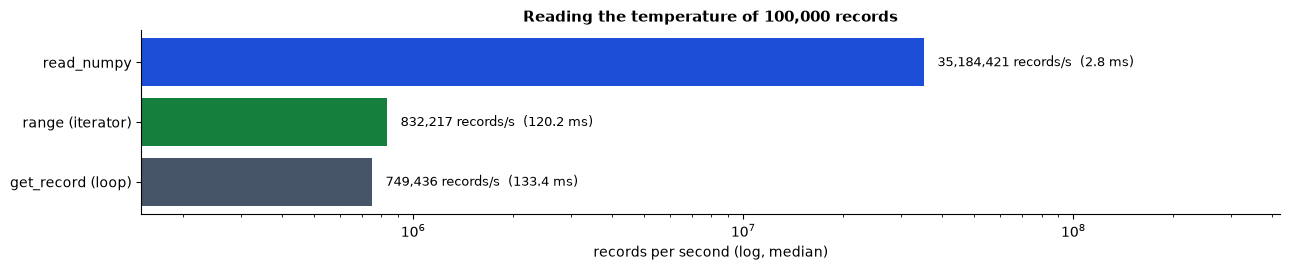

In [4]:
N_READ = 100_000
db, READ_PATH = new_sensor_db("read.nhydb")
db.put_numpy_batch(1, 1, columns(N_READ), shape_id=1, commit=True)
db.close()

reads = []
with nhydb.open(READ_PATH) as db:
    for name, fn in (
        ("get_record (loop)", lambda: [db.get_record(1, u)["temp"] for u in range(1, N_READ + 1)]),
        ("range (iterator)",  lambda: [r["temp"] for r in db.range(1, 1, N_READ)]),
        ("read_numpy",        lambda: db.read_numpy(1, 1, N_READ, ["temp"])["temp"]),
    ):
        times = []
        for _ in range(REPEATS):
            t0 = time.perf_counter()
            values = fn()
            times.append(time.perf_counter() - t0)
        assert len(values) == N_READ
        reads.append({"path": name, "median s": statistics.median(times),
                      "records/s": N_READ / statistics.median(times)})
reads = pd.DataFrame(reads).set_index("path")

fig, ax = plt.subplots(figsize=(13, 2.8))
colors = [COLORS["C"], COLORS["B"], COLORS["A"]]
ax.barh(reads.index, reads["records/s"], color=colors)
ax.set_xscale("log")
for i, (name, row) in enumerate(reads.iterrows()):
    ax.text(row["records/s"] * 1.1, i, f"{row['records/s']:,.0f} records/s  ({row['median s'] * 1000:.1f} ms)",
            va="center", fontsize=9)
ax.set_xlim(reads["records/s"].min() / 5, reads["records/s"].max() * 12)
ax.set_xlabel("records per second (log, median)")
ax.set_title(f"Reading the temperature of {N_READ:,} records")
plt.tight_layout()
plt.show()

### What comes back: data types and `_present`

`read_numpy` returns one array per field plus a boolean array `_present`. Records that do not
exist are reported as missing (values `0`, `NaN` or `None`) instead of raising an error – useful
for gaps.

In [5]:
with nhydb.open(READ_PATH) as db:
    out = db.read_numpy(1, N_READ - 1, 4, ["t", "temp", "ok", "station"])     # the last 2 exist, 2 do not

pd.DataFrame({name: [str(arr.dtype), arr.tolist()] for name, arr in out.items()},
             index=["dtype", "values"]).T

,dtype,values
t,uint64,"[5999880, 5999940, 0, 0]"
temp,float32,"[24.9991512298584, 24.99692153930664, nan, nan]"
ok,bool,"[True, True, False, False]"
station,object,"[C, D, None, None]"
_present,bool,"[True, True, False, False]"


In [6]:
assert out["_present"].tolist() == [True, True, False, False]
assert out["t"].dtype == np.uint64 and out["temp"].dtype == np.float32 and out["station"].dtype == object
print("u64 comes back as uint64, f32 as float32, bool as bool, utf8 as an object array; missing records are flagged.")

u64 comes back as uint64, f32 as float32, bool as bool, utf8 as an object array; missing records are flagged.


## 3 · What a value costs on disk: dense records vs. sparse cells

**Question:** Is it cheaper to store data as records or as loose cells?

Dense records (batches of a CLASSIC layout) store only the encoded values in large blocks.
Sparse cells (`put_cell`, `put_cells_numpy`) must remember their coordinates. We store the same
40,000 temperature values four ways – as records, as sparse cells in one NumPy call (two
arrangements), and as 40,000 single `put_cell` calls.

In [7]:
N_VALUES = 40_000
temps = (20 + 5 * np.sin(np.arange(N_VALUES) / 60.0)).astype(np.float64)

dense = db_path("dense.nhydb")
with nhydb.create(dense) as db:
    db.create_realm(1, "r")
    db.create_shape(1, 1, "s", [{"v": 1, "name": "temp", "type": "f64"}])
    db.create_classic_layout(1, 1, "temps", shape_id=1)
    db.put_numpy_batch(1, 1, {"temp": temps})

sparse = db_path("sparse.nhydb")
with nhydb.create(sparse) as db:
    db.create_realm(1, "r")
    u = np.arange(1, N_VALUES + 1, dtype=np.uint64)
    db.put_cells_numpy(1, u, np.ones(N_VALUES, dtype=np.uint64), temps, type="f64")   # cells (u, v=1)

sparse_grid = db_path("sparse_grid.nhydb")
with nhydb.create(sparse_grid) as db:
    db.create_realm(1, "r")
    side = int(N_VALUES ** 0.5)
    u = (np.arange(N_VALUES) // side + 1).astype(np.uint64)
    v = (np.arange(N_VALUES) % side + 1).astype(np.uint64)
    db.put_cells_numpy(1, u, v, temps, type="f64")                                       # a 200 × 200 grid

single_cells = db_path("single_cells.nhydb")
with nhydb.create(single_cells) as db:
    db.create_realm(1, "r")
    for i, value in enumerate(temps.tolist()):
        db.put_cell(1, i + 1, 1, value, type="f64")                                      # one call per value

costs = pd.DataFrame([
    {"how": "dense records (put_numpy_batch)", "file bytes": os.path.getsize(dense)},
    {"how": "sparse cells, one per u (put_cells_numpy)", "file bytes": os.path.getsize(sparse)},
    {"how": "sparse cells, 200 × 200 grid", "file bytes": os.path.getsize(sparse_grid)},
    {"how": "40,000 single put_cell calls", "file bytes": os.path.getsize(single_cells)},
])
costs["bytes per value"] = ((costs["file bytes"] - 8192) / N_VALUES).round(1)
with nhydb.open(sparse_grid) as db:
    assert db.get_value(1, 200, 200) == temps[-1]
costs

,how,file bytes,bytes per value
0,dense records (put_numpy_batch),489144,12.0
1,"sparse cells, one per u (put_cells_numpy)",529296,13.0
2,"sparse cells, 200 × 200 grid",410176,10.0
3,"40,000 single put_cell calls",2438080,60.7


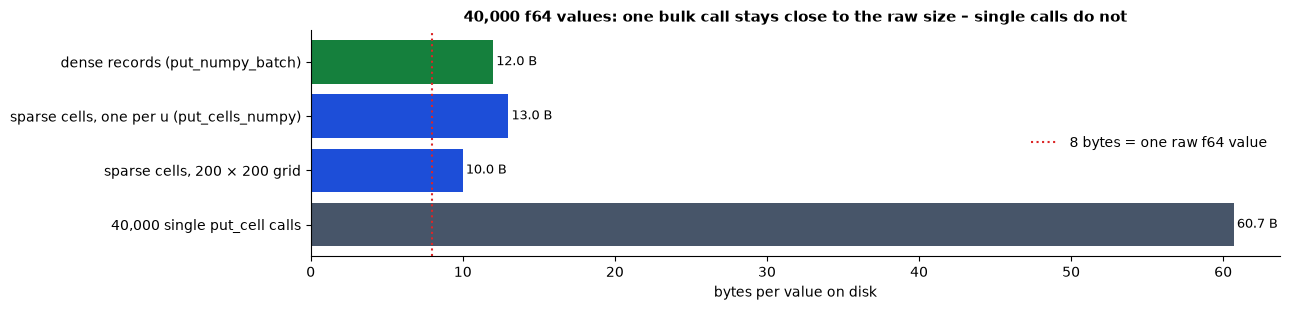

In [8]:
fig, ax = plt.subplots(figsize=(13, 2.8))
fig.set_figheight(3.2)
ax.barh(costs["how"], costs["bytes per value"], color=[COLORS["B"], COLORS["A"], COLORS["A"], COLORS["C"]])
ax.axvline(8, color=COLORS["bad"], ls=":", lw=1.5, label="8 bytes = one raw f64 value")
ax.legend(frameon=False, loc="center right")
for i, b in enumerate(costs["bytes per value"]):
    ax.text(b + 0.2, i, f"{b} B", va="center", fontsize=9)
ax.invert_yaxis()
ax.set_xlabel("bytes per value on disk")
ax.set_title(f"{N_VALUES:,} f64 values: one bulk call stays close to the raw size – single calls do not")
plt.tight_layout()
plt.show()

**What happened?** A surprise for many: dense records and sparse cells written **in one bulk
call** all stay close to the raw 8 bytes of a `f64`. Dense records keep the record number
implicit (consecutive `u`); sparse cells are grouped in windows of `u`, so their coordinates
cost only a byte or two each – the 200 × 200 grid is even the most compact, because many cells
share one `u`. What really costs space is **calling once per value**: every single `put_cell`
becomes a small block with its own header. **Ah – it is not "records vs. cells" that matters,
it is "one call vs. many calls".**

## 4 · NumPy everywhere: objects, MATH layouts and SQL

**Question:** Does NumPy only work for consecutive CLASSIC records?

No. `put_objects_numpy` writes objects of **any** layout by object id, `put_math_numpy` feeds
input tuples to a MATH layout (notebook 05), and `sql_numpy` / `execute_numpy` return query
results as columns.

In [9]:
MIX = db_path("mix.nhydb")
with nhydb.create(MIX) as db:
    db.create_realm(1, "points")
    db.create_shape(1, 1, "p", [{"v": 1, "name": "id", "type": "varuint"}, {"v": 2, "name": "x", "type": "f64"}])
    db.create_classic_layout(1, 1, "points", shape_id=1)
    ids = np.array([3, 5, 8, 13, 21, 34, 55, 89], dtype=np.uint64)            # Fibonacci object ids
    db.put_objects_numpy(1, ids, {"id": ids, "x": np.sqrt(ids.astype(np.float64))})

    sq = MathMap.compile("squares", ("k",), u="k", V="k * k", side="NR")      # cell (k, k², NR)
    db.create_math_layout(MathMapLayoutSpec("squares", sq, 64), layout_id=2, payload_type="f64")
    k = np.arange(1, 1001, dtype=np.int64)
    db.put_math_numpy(2, k, np.log(k.astype(np.float64)), commit=True)

    fib = db.sql_numpy("SELECT id, x FROM points WHERE id > ? ORDER BY id", [10])
    big_x = QueryEngine(db).execute_numpy(Q.field("x") > 5, realm=1, select=["id"])
    math_cell = db.get_math_cell(2, (12,))

print("sql_numpy        :", fib)
print("execute_numpy    :", big_x)
print("MATH cell of k=12:", {key: math_cell[key] for key in ("_realm", "_u", "_v", "_lane_name", "value")})
assert list(fib["id"]) == [13, 21, 34, 55, 89] and math_cell["_v"] == 144

sql_numpy        : {'id': array([13, 21, 34, 55, 89]), 'x': array([3.60555128, 4.58257569, 5.83095189, 7.41619849, 9.43398113])}
execute_numpy    : {'record_N': array(['N1191', 'N3081', 'N8011'], dtype=object), 'id': array([34, 55, 89])}
MATH cell of k=12: {'_realm': 2, '_u': 12, '_v': 144, '_lane_name': 'NR', 'value': 2.4849066497880004}


## Your turn

**Task:** write 50,000 samples with `put_numpy_batch`, read them back with `read_numpy` and
check that every column is **identical** to what you wrote.

In [10]:
N_TASK = 50_000
cols = columns(N_TASK)
db, path = new_sensor_db("task.nhydb")
db.put_numpy_batch(1, 1, cols, shape_id=1, commit=True)
back = db.read_numpy(1, 1, N_TASK, ["t", "temp", "ok", "station"])
db.close()

assert back["_present"].all()
assert np.array_equal(back["t"], cols["t"])
assert np.array_equal(back["temp"], cols["temp"])                      # f32 values are stored exactly
assert np.array_equal(back["ok"], cols["ok"]) and list(back["station"]) == list(cols["station"])
print(f"{N_TASK:,} records, 4 columns: identical after the round trip ✓")

50,000 records, 4 columns: identical after the round trip ✓


## ⏩ Advanced: input is checked before anything is written

Wrong lengths, values out of range or unknown fields raise an error **before** the first byte
is written – a NumPy batch never leaves half of itself in the file.

In [11]:
db, path = new_sensor_db("checks.nhydb")
bad_inputs = {
    "columns of different length": {"t": np.arange(5, dtype=np.uint64), "temp": np.zeros(4, np.float32),
                                    "ok": np.ones(5, bool), "station": np.array(["A"] * 5, dtype=object)},
    "negative value for u64":      {"t": np.array([-1, 2]), "temp": np.zeros(2, np.float32),
                                    "ok": np.ones(2, bool), "station": np.array(["A"] * 2, dtype=object)},
}
for label, cols_bad in bad_inputs.items():
    try:
        db.put_numpy_batch(1, 1, cols_bad, shape_id=1)
        raise AssertionError("should have failed")
    except ValueError as e:
        print(f"{label:30} → ValueError: {e}")
db.commit()
assert db.get_record(1, 1) is None                                     # nothing was written
db.close()

columns of different length    → ValueError: Column 'temp' has 4 values, expected 5
negative value for u64         → ValueError: t: -1 does not fit into u64


## Summary

* Single calls, `put_dense_batch` and `put_numpy_batch` produce the same cells; batches pay the call cost once.
* Batches are not only faster but also smaller on disk: dense blocks store just the encoded values.
* `read_numpy` returns typed columns plus `_present`; missing records are flagged, not errors.
* Sparse cells carry their coordinates – use records for regular data, cells for scattered data.
* NumPy works for any layout (`put_objects_numpy`), MATH layouts (`put_math_numpy`) and query results (`sql_numpy`).

## Where to go next

* [13 · Benchmark Lab](13_benchmark_lab_v1.ipynb) – write, index and read phases measured in detail.
* [11 · What Actually Lives on Disk?](11_what_lives_on_disk_v1.ipynb) – blocks, commits and the file layout.
* [09 · Asking Questions](09_queries_and_sql_v1.ipynb) – queries and SQL.

**Cookbook sections:** 16 (NumPy batch API), 18 (MATH_MAP, `put_math_numpy`), 7 (Single cells) in the [NHyDB Python Cookbook](https://github.com/nhydb/NHyDB/blob/main/docs/cookbook/PYTHON_COOKBOOK.md).

In [12]:
# Clean up: remove the temporary folder with all databases of this notebook.
cleanup()
print("Temporary files removed.")

Temporary files removed.
